# Lab 2 — Global Post-hoc Explainability


---

This lab covers three **global post-hoc** explainability techniques applied to black-box classifiers on the Titanic dataset:

| Technique | What it explains |
|---|---|
| **Permutation Feature Importance** | How much each feature contributes to model performance |
| **Partial Dependence Plot (PDP)** | Marginal effect of one (or two) features on the predicted outcome |
| **Global Surrogate Models** | A white-box model that approximates a black-box model's predictions |

**Guide:**
- ⚙️ Data preprocessing (Titanic)
- 🔀 Permutation Feature Importance
- 📉 Partial Dependence Plots
- 🪞 Global Surrogate Models


## ⚙️ Data Preprocessing (~10 min)

We are using the **Titanic** dataset loaded directly from OpenML.
This section walks through the full preprocessing pipeline: loading, splitting, imputing, encoding, and scaling.

> 💡 Apply the same good habits from Lab 1: always fit transformations on the **training set only**, then apply them to the test set!


### ⚙️ Step 1 — Imports & Load

In [ ]:
# Import the required libraries for this exercise

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn import tree

import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

### ⚙️ Step 2 — Load the Titanic Dataset

In [ ]:
# Load input features and target variable
df, y = fetch_openml("titanic", version=1, as_frame=True, parser='auto', return_X_y=True)

# The "survived" column contains the target variable
df["survived"] = y

print(f"Dataset shape: {df.shape}")
df.head()

/usr/local/lib/python3.13/dist-packages/sklearn/datasets/_openml.py:110: UserWarning: A network error occurred while downloading https://api.openml.org/api/v1/json/data/list/data_name/titanic/limit/2/data_version/1. Retrying...
  warn(


HTTPError: HTTP Error 503: Service Temporarily Unavailable

In [ ]:
# Quick overview
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [ ]:
# Class balance — important for choosing metrics!
print("Class distribution:")
print(df["survived"].value_counts())
print(f"\nImbalance ratio: {df['survived'].value_counts()[0]/df['survived'].value_counts()[1]:.2f}:1")

Class distribution:
survived
0    549
1    342
Name: count, dtype: int64

Imbalance ratio: 1.61:1


### ⚙️ Step 3 — Stratified Train / Test Split

> 🔑 **Key reminder:** split *before* any transformation. Fitting scalers or imputers on the full dataset causes **data leakage**.


In [ ]:
# Split the dataset. 80% for training data and 20% for test data. Shuffle the dataset and perform stratification by label
df_train, df_test = train_test_split(df, test_size=0.2, shuffle=True, random_state=42, stratify=df['survived'])


print(f"Train: {len(df_train)} samples | Test: {len(df_test)} samples")
print("\nTrain class distribution:")
print(df_train["survived"].value_counts())

Train: 712 samples | Test: 179 samples

Train class distribution:
survived
0    439
1    273
Name: count, dtype: int64


### ⚙️ Step 4 — Handle Missing Values

> 🔑 **Key reminder:** compute statistics (mean, median…) on the **training set only**, then apply to both sets.


In [ ]:
#### START CODE HERE #### (~5-6 lines of code)
# Count NaN per column and print
nan_train = df_train.isna().sum()
nan_test  = df_test.isna().sum()

print("Missing values — Train:")
print(nan_train[nan_train > 0])
print("\nMissing values — Test:")
print(nan_test[nan_test > 0])

#### END CODE HERE ####

Missing values — Train:
age            137
embarked         2
deck           553
embark_town      2
dtype: int64

Missing values — Test:
age      40
deck    135
dtype: int64


In [ ]:
print(f'Number of null values in Train before pre-processing: {df_train.age.isnull().sum()}/{len(df_train)}')
print(f'Number of null values in Test before pre-processing: {df_test.age.isnull().sum()}/{len(df_test)}')

df_train['age'] = df_train['age'].fillna(df_train['age'].mean())
df_test['age'] = df_test['age'].fillna(df_train['age'].mean())

print(f'Number of null values in Train after pre-processing: {df_train.age.isnull().sum()}/{len(df_train)}')
print(f'Number of null values in Test after pre-processing: {df_test.age.isnull().sum()}/{len(df_test)}')

Number of null values in Train before pre-processing: 137/712
Number of null values in Test before pre-processing: 40/179
Number of null values in Train after pre-processing: 0/712
Number of null values in Test after pre-processing: 0/179


In [ ]:
print(f'Number of null values in Train before pre-processing: {df_train.fare.isnull().sum()}/{len(df_train)}')
print(f'Number of null values in Test before pre-processing: {df_test.fare.isnull().sum()}/{len(df_test)}')

df_train['fare'] = df_train['fare'].fillna(df_train['fare'].median())
df_test['fare'] = df_test['fare'].fillna(df_train['fare'].median())

print(f'Number of null values in Train after pre-processing: {df_train.fare.isnull().sum()}/{len(df_train)}')
print(f'Number of null values in Test after pre-processing: {df_test.fare.isnull().sum()}/{len(df_test)}')

Number of null values in Train before pre-processing: 0/712
Number of null values in Test before pre-processing: 0/179
Number of null values in Train after pre-processing: 0/712
Number of null values in Test after pre-processing: 0/179


In [ ]:
print(f'Number of null values in Train before pre-processing: {df_train.embarked.isnull().sum()}/{len(df_train)}')
print(f'Number of null values in Test before pre-processing: {df_test.embarked.isnull().sum()}/{len(df_test)}')

imp = SimpleImputer(missing_values=np.nan, strategy='most_frequent')
df_train[['embarked']] = imp.fit_transform(df_train[['embarked']])
df_test[['embarked']] = imp.transform(df_test[['embarked']])

print(f'Number of null values in Train after pre-processing: {df_train.embarked.isnull().sum()}/{len(df_train)}')
print(f'Number of null values in Test after pre-processing: {df_test.embarked.isnull().sum()}/{len(df_test)}')

Number of null values in Train before pre-processing: 2/712
Number of null values in Test before pre-processing: 0/179
Number of null values in Train after pre-processing: 0/712
Number of null values in Test after pre-processing: 0/179


### ⚙️ Step 5 — Drop Uninformative Columns

> 🔑 Remove columns that are not useful for predicting survival, or that leak information about the target variable.


In [ ]:
df_train = df_train.drop(columns=['name','ticket'])
df_test = df_test.drop(columns=['name','ticket'])

df_train.head()

KeyError: "['name', 'ticket'] not found in axis"

In [ ]:
# Remove columns that contain target-leaking info (boat/body) or are mostly missing (cabin, home.dest)
df_train = df_train.drop(columns=['cabin', 'body', 'boat', 'home.dest'])
df_test = df_test.drop(columns=['cabin', 'body', 'boat', 'home.dest'])

### ⚙️ Step 6 — Extract Features & Apply Encoding / Scaling

> 🔑 **Key reminder:** ML models need numbers. We use `OneHotEncoder` for categoricals and `MinMaxScaler` for numerics — both fitted on **train only**.


In [ ]:
# Extract target variable and input features for the training data
y_train = df_train['survived']               # Target variable training set
X_train = df_train.drop('survived', axis=1)  # Features training set

# Extract target variable and input features for the testing data
y_test = df_test['survived']                 # Target variable test set
X_test = df_test.drop('survived', axis=1)    # Features test set

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.preprocessing import MinMaxScaler

categorical_columns = ["pclass", "sex", "embarked"]
numerical_columns = ["sibsp", "parch", "fare", "age"]

categorical_encoder = OneHotEncoder(handle_unknown='ignore', drop='if_binary')
minmax_s = MinMaxScaler()

preprocessing = ColumnTransformer(
    [
        ("cat", categorical_encoder, categorical_columns),
        ("num", minmax_s, numerical_columns),
    ],
    verbose_feature_names_out=False,
)

> ✅ **Preprocessing complete.** Remember the three rules:
> 1. Split *before* fitting any transformer.
> 2. Fit transformers on **train only**, apply to both.
> 3. Use `ColumnTransformer` to cleanly handle mixed-type features in a `Pipeline`.


## Exercise 1 — Permutation Feature Importance 🔀

**Permutation Feature Importance** is a model-agnostic inspection technique that measures how much each feature contributes to model performance.

> A feature is **important** if shuffling its values causes the *model error to increase*. If the model relied on that feature, disrupting it should hurt performance.

**Key advantages:**
- Direct and intuitive interpretation of the model's behaviour
- Fully **model-agnostic** — works with any fitted estimator
- Does **not require retraining** the model

**Main disadvantages:**
- Assumes **feature independence** — correlated features can produce biased importance estimates
- Tightly coupled to the chosen **performance metric**


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.datasets import make_classification

### 1.1 — Fit the Random Forest Classifier

In [ ]:


clf = Pipeline(
    [
        ("preprocess", preprocessing),
        ("classifier", RandomForestClassifier(random_state=42)),
    ]
)
clf.fit(X_train, y_train)
clf.transform(X_test, y_test)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(drop='if_binary',
                                                                handle_unknown='ignore'),
                                                  ['pclass', 'sex',
                                                   'embarked']),
                                                 ('num', MinMaxScaler(),
                                                  ['sibsp', 'parch', 'fare',
                                                   'age'])],
                                   verbose_feature_names_out=False)),
                ('classifier', RandomForestClassifier(random_state=42))])

### 1.2 — Model Performance

> Before inspecting feature importances, verify the model is predictive enough. A non-predictive model's importances are meaningless.


In [ ]:
print(f"RF train accuracy: {clf.score(X_train, y_train):.3f}")
print(f"RF test accuracy: {clf.score(X_test, y_test):.3f}")

RF train accuracy: 0.969
RF test accuracy: 0.779



### 1.3 — Built-in Feature Importances

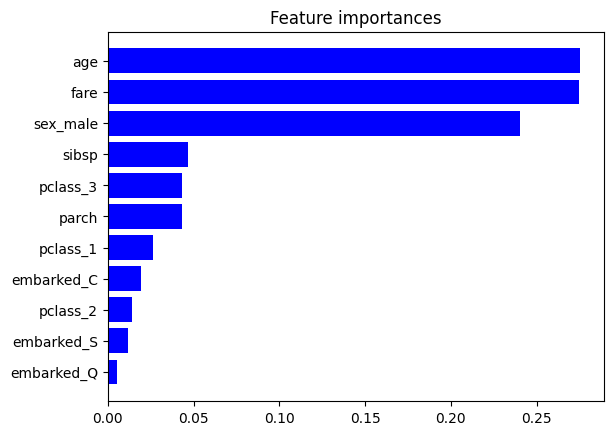

In [ ]:
# Plot the feature importance (raw, per one-hot column)

importance = clf[-1].feature_importances_
feature_names = clf[:-1].get_feature_names_out()

sorted_idx = importance.argsort()

plt.barh(feature_names[sorted_idx], importance[sorted_idx], color='blue')
plt.title("Feature importances")
plt.show()

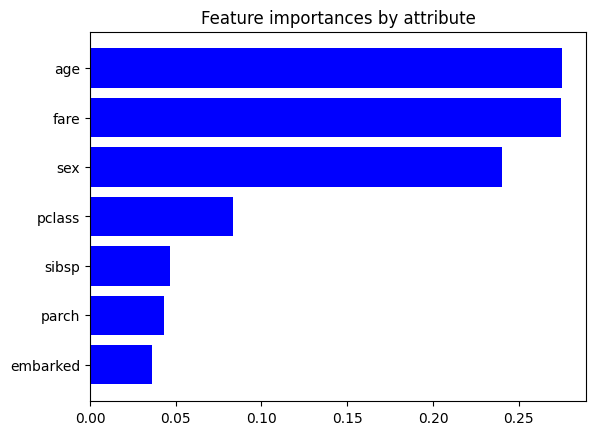

In [ ]:
# Plot the feature importance aggregated by original attribute

importance = clf[-1].feature_importances_
feature_names = clf[:-1].get_feature_names_out()

feature_importances = {}
for feature_name, imp in zip(feature_names, importance):
    key = feature_name.split("_")[0] if "_" in feature_name else feature_name
    feature_importances[key] = feature_importances.get(key, 0) + imp

feature_importances = dict(sorted(feature_importances.items(), key=lambda x: x[1], reverse=False))

plt.barh(list(feature_importances.keys()), list(feature_importances.values()), color='blue')
plt.title("Feature importances by attribute")
plt.show()

The impurity-based feature importance ranks the **numerical features** to be the **most important** features.

This stems from two known **limitations** of impurity-based importances:
- Importances are biased towards *high-cardinality features* (e.g. `fare`, `age`).
- Importances are computed on **training set statistics** and may not reflect generalisation ability.


### 1.4 — Permutation Importance on the Test Set

Text(0.5, 0, 'Decrease in accuracy score')

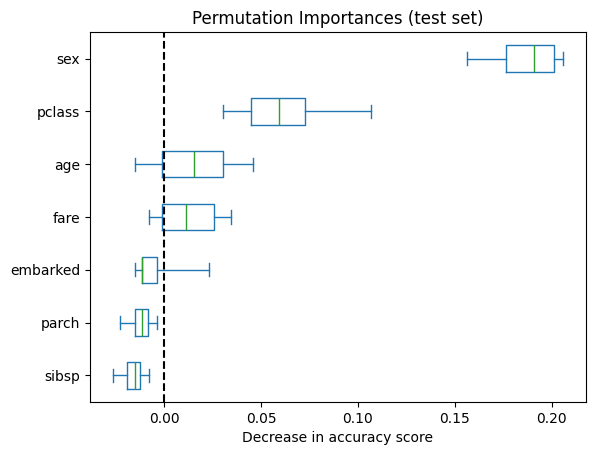

In [ ]:
from sklearn.inspection import permutation_importance

# Calculate the permutation importance of each feature — test set
result = permutation_importance(clf, X_test, y_test, n_repeats=10, random_state=42)

sorted_importances_idx = result.importances_mean.argsort()
importances = pd.DataFrame(
    result.importances[sorted_importances_idx].T,
    columns=X_test.columns[sorted_importances_idx],
)
ax = importances.plot.box(vert=False, whis=5)
ax.set_title("Permutation Importances (test set)")
ax.axvline(x=0, color="k", linestyle="--")
ax.set_xlabel("Decrease in accuracy score")

The low-cardinality categorical features `sex` and `pclass` are now ranked as the **most important** features. Permuting their values causes the **largest drop in accuracy** on the test set — confirming they drive the model's generalisation.


### 1.5 — Permutation Importance on the Training Set

Text(0.5, 0, 'Decrease in accuracy score')

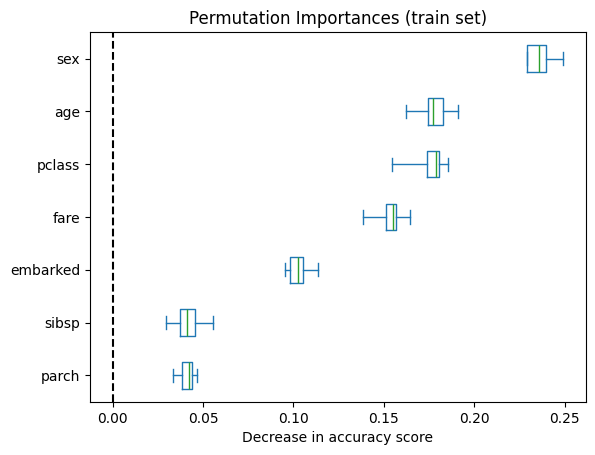

In [ ]:
# Calculate the permutation importance of each feature — train set
result = permutation_importance(clf, X_train, y_train, n_repeats=10, random_state=42)

sorted_importances_idx = result.importances_mean.argsort()
importances = pd.DataFrame(
    result.importances[sorted_importances_idx].T,
    columns=X_train.columns[sorted_importances_idx],
)
ax = importances.plot.box(vert=False, whis=5)
ax.set_title("Permutation Importances (train set)")
ax.axvline(x=0, color="k", linestyle="--")
ax.set_xlabel("Decrease in accuracy score")

> `fare` gets a **significantly higher** importance ranking on the training set than on the test set. This discrepancy is a clear sign of **overfitting**: the Random Forest has enough capacity to use `fare` to memorise training examples, but this does not generalise.


### 1.6 — Regularised Random Forest (`min_samples_leaf=20`)

In [ ]:
# Limit tree capacity to prevent overfitting
clf = Pipeline(
    [
        ("preprocess", preprocessing),
        ("classifier", RandomForestClassifier(random_state=42, min_samples_leaf=20)),
    ]
)
clf.fit(X_train, y_train)
clf.transform(X_test, y_test)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(drop='if_binary',
                                                                handle_unknown='ignore'),
                                                  ['pclass', 'sex',
                                                   'embarked']),
                                                 ('num', MinMaxScaler(),
                                                  ['sibsp', 'parch', 'fare',
                                                   'age'])],
                                   verbose_feature_names_out=False)),
                ('classifier',
                 RandomForestClassifier(min_samples_leaf=20, random_state=42))])

In [ ]:
print(f"RF train accuracy: {clf.score(X_train, y_train):.3f}")
print(f"RF test accuracy: {clf.score(X_test, y_test):.3f}")

RF train accuracy: 0.808
RF test accuracy: 0.847


Train and test accuracy are now very close — the model is **no longer overfitting**. We can now trust the permutation importance results.


Text(0.5, 0, 'Decrease in accuracy score')

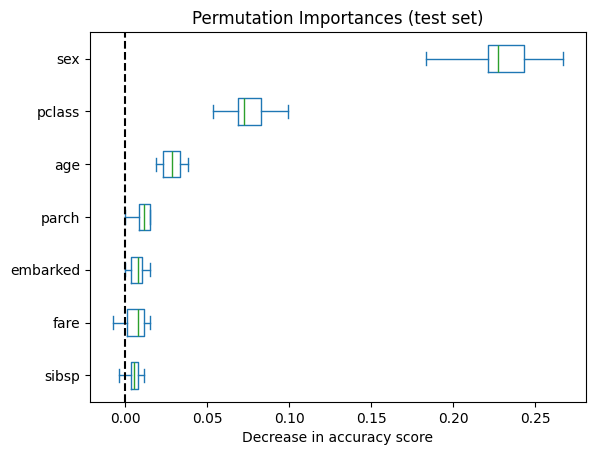

In [ ]:
# Permutation importance (test set) — regularised model
result = permutation_importance(clf, X_test, y_test, n_repeats=10, random_state=42)

sorted_importances_idx = result.importances_mean.argsort()
importances = pd.DataFrame(
    result.importances[sorted_importances_idx].T,
    columns=X_test.columns[sorted_importances_idx],
)
ax = importances.plot.box(vert=False, whis=5)
ax.set_title("Permutation Importances (test set)")
ax.axvline(x=0, color="k", linestyle="--")
ax.set_xlabel("Decrease in accuracy score")

Text(0.5, 0, 'Decrease in accuracy score')

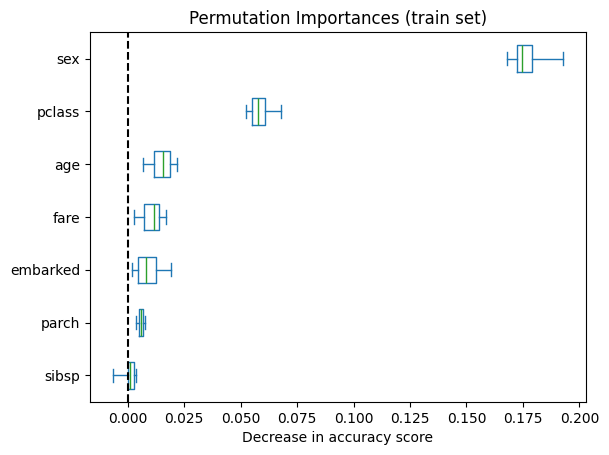

In [ ]:
# Permutation importance (train set) — regularised model
result = permutation_importance(clf, X_train, y_train, n_repeats=10, random_state=42)

sorted_importances_idx = result.importances_mean.argsort()
importances = pd.DataFrame(
    result.importances[sorted_importances_idx].T,
    columns=X_train.columns[sorted_importances_idx],
)
ax = importances.plot.box(vert=False, whis=5)
ax.set_title("Permutation Importances (train set)")
ax.axvline(x=0, color="k", linestyle="--")
ax.set_xlabel("Decrease in accuracy score")

## Exercise 2 — Partial Dependence Plots 📉

A **Partial Dependence Plot** (PDP) shows the **marginal effect** of one (or two) features on the predicted outcome of a machine learning model.

- It is a **global method**: it considers *all instances* and describes the global relationship between a feature and the prediction.
- PDPs are easy to visualise and intuitively interpretable.

**Key advantages:**
- Computation is intuitive and the visualisation is easy to read.
- Provides a global view of how a feature influences the prediction.

**Main disadvantages:**
- Assumes **feature independence** — correlated features distort the marginal estimates.
- Only practical for **at most two features** at a time.


### 2.1 — Imports

In [ ]:
from sklearn.inspection import permutation_importance, partial_dependence, PartialDependenceDisplay
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.datasets import make_classification

### 2.2 — Fit RF & DT Classifiers

In [ ]:
# Random Forest classifier
rf = Pipeline(
    [
        ("preprocess", preprocessing),
        ("classifier", RandomForestClassifier(random_state=42)),
    ]
)
rf.fit(X_train, y_train)

print(f"RF train accuracy: {rf.score(X_train, y_train):.3f}")
print(f"RF test accuracy:  {rf.score(X_test, y_test):.3f}")

RF train accuracy: 0.969
RF test accuracy:  0.779


In [ ]:
# Decision Tree classifier
dt = Pipeline(
    [
        ("preprocess", preprocessing),
        ("classifier", DecisionTreeClassifier(random_state=42)),
    ]
)
dt.fit(X_train, y_train)

print(f"DT train accuracy: {dt.score(X_train, y_train):.3f}")
print(f"DT test accuracy:  {dt.score(X_test, y_test):.3f}")

DT train accuracy: 0.969
DT test accuracy:  0.771


### 2.3 — Feature Importances

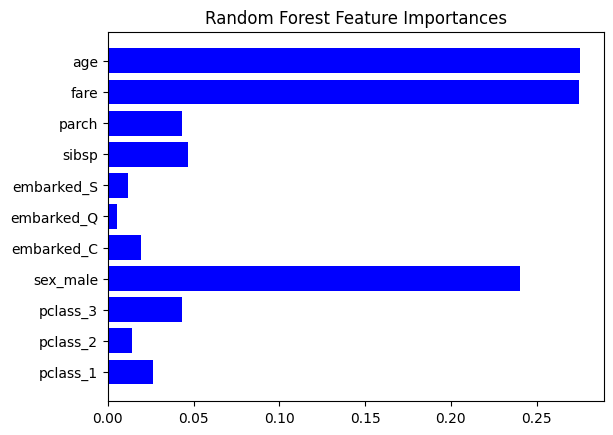

In [ ]:
# Feature importance — Random Forest
importance = rf[-1].feature_importances_
feature_names = rf[:-1].get_feature_names_out()

plt.barh(feature_names, importance, color='blue')
plt.title("Random Forest Feature Importances")
plt.show()

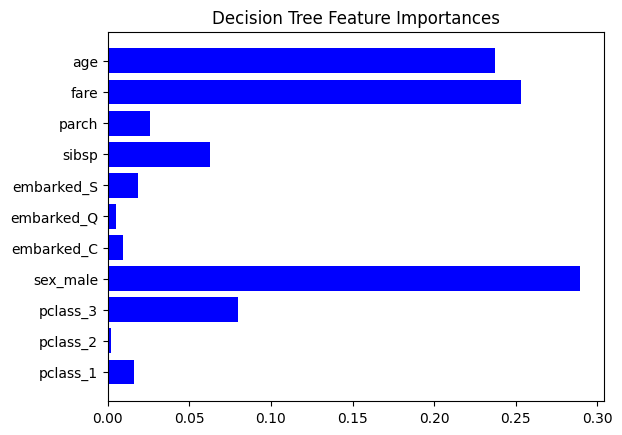

In [ ]:
# Feature importance — Decision Tree
importance = dt[-1].feature_importances_
feature_names = dt[:-1].get_feature_names_out()

plt.barh(feature_names, importance, color='blue')
plt.title("Decision Tree Feature Importances")
plt.show()

### 2.4 — Partial Dependence Plots

In [ ]:
X_train.columns.tolist()

['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']

In [ ]:
categorical_columns

['pclass', 'sex', 'embarked']

In [ ]:
feature_names

array(['pclass_1', 'pclass_2', 'pclass_3', 'sex_male', 'embarked_C',
       'embarked_Q', 'embarked_S', 'sibsp', 'parch', 'fare', 'age'],
      dtype=object)

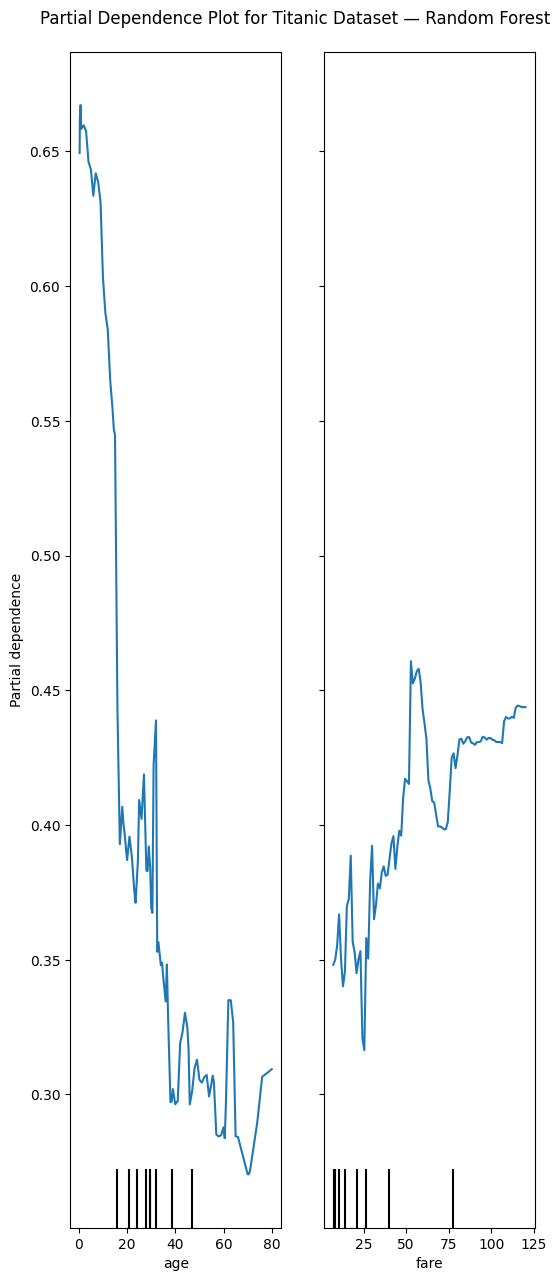

In [ ]:
# Select a subset of features to display in the PDP
selected_features = ['age', 'fare']

# PDP — Random Forest
fig, ax = plt.subplots(figsize=(6, 14))

display = PartialDependenceDisplay.from_estimator(
    rf,
    X_train,
    features=selected_features,
    n_cols=4,
    categorical_features=categorical_columns,
    ax=ax
)

display.figure_.suptitle('Partial Dependence Plot for Titanic Dataset — Random Forest')
display.figure_.subplots_adjust(hspace=0.4, top=0.95)
plt.show()

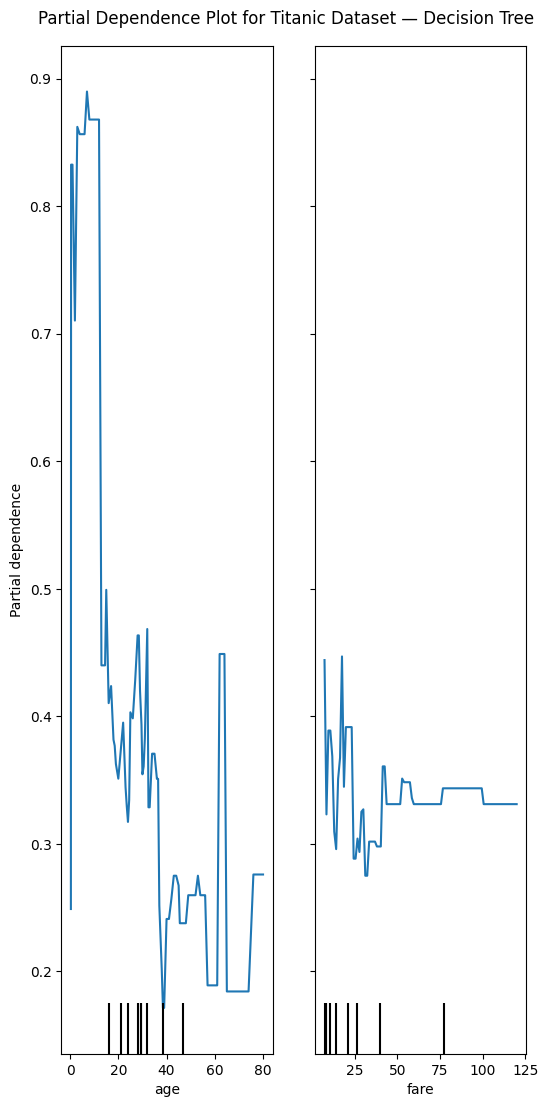

In [ ]:
feature_names = X_train.columns

# PDP — Decision Tree
fig, ax = plt.subplots(figsize=(6, 12))

display = PartialDependenceDisplay.from_estimator(
    dt,
    X_train,
    features=selected_features,
    n_cols=2,
    categorical_features=categorical_columns,
    ax=ax
)

display.figure_.suptitle('Partial Dependence Plot for Titanic Dataset — Decision Tree')
display.figure_.subplots_adjust(hspace=0.4, top=0.95)
plt.show()

## Exercise 3 — Global Surrogate Models 🪞

A **global surrogate model** is an *interpretable* model trained to **approximate** the predictions of a black-box model as accurately as possible.

> The key idea: you don't need to peek inside the black box — only its **prediction function** and a dataset are required.

**How to build a surrogate:**
1. Select a dataset X.
2. Get the **black-box predictions** for X.
3. Choose an **interpretable model type** (linear model, decision tree, …).
4. Train the interpretable model on X using the black-box predictions as labels.
5. Measure how well the surrogate **replicates** the black-box predictions (reconstruction error).

The surrogate is **model-agnostic** — it makes no assumptions about the inner workings of the black-box model.


### 3.1 — Imports

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier
import numpy as np
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

### 3.2 — Train the Black-Box Model

In [ ]:
# Train the black-box model (GradientBoostingClassifier)
black_box_model = Pipeline(
    [
        ("preprocess", preprocessing),
        ("classifier", GradientBoostingClassifier(n_estimators=100, random_state=42)),
    ]
)
black_box_model.fit(X_train, y_train)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(drop='if_binary',
                                                                handle_unknown='ignore'),
                                                  ['pclass', 'sex',
                                                   'embarked']),
                                                 ('num', MinMaxScaler(),
                                                  ['sibsp', 'parch', 'fare',
                                                   'age'])],
                                   verbose_feature_names_out=False)),
                ('classifier', GradientBoostingClassifier(random_state=42))])

### 3.3 — Train the White-Box Surrogate

In [ ]:
# Train the white-box surrogate (Logistic Regression) on the black-box predictions
white_box_model = Pipeline(
    [
        ("preprocess", preprocessing),
        ("classifier", LogisticRegression(max_iter=1000, random_state=42)),
    ]
)

black_box_train_predictions = black_box_model.predict(X_train)

# The surrogate is trained to replicate the black-box output, not the true labels
white_box_model.fit(X_train, black_box_train_predictions)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(drop='if_binary',
                                                                handle_unknown='ignore'),
                                                  ['pclass', 'sex',
                                                   'embarked']),
                                                 ('num', MinMaxScaler(),
                                                  ['sibsp', 'parch', 'fare',
                                                   'age'])],
                                   verbose_feature_names_out=False)),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42))])

### 3.4 — Inspect Surrogate Coefficients

In [ ]:
# Extract coefficients and compute odds ratios
coefficients = white_box_model[1].coef_[0]
feature_names = white_box_model[:-1].get_feature_names_out()

odds_ratios = np.exp(coefficients)

results_df = pd.DataFrame({
    'Feature': feature_names,
    'Weight': coefficients,
    'Odds Ratio': odds_ratios
})

print(results_df)

       Feature    Weight  Odds Ratio
0     pclass_1  1.405170    4.076221
1     pclass_2  0.530692    1.700108
2     pclass_3 -1.925615    0.145786
3     sex_male -4.247295    0.014303
4   embarked_C  0.518761    1.679945
5   embarked_Q  0.258913    1.295521
6   embarked_S -0.767426    0.464206
7        sibsp -1.025828    0.358499
8        parch  0.271571    1.312025
9         fare  0.208645    1.232008
10         age -3.382159    0.033974


### 3.5 — Evaluate Both Models

In [ ]:
# Accuracy of the black-box and white-box models on true labels
black_box_train_accuracy = accuracy_score(y_train, black_box_train_predictions)
black_box_test_accuracy  = accuracy_score(y_test, black_box_model.predict(X_test))
white_box_train_accuracy = accuracy_score(y_train, white_box_model.predict(X_train))
white_box_test_accuracy  = accuracy_score(y_test, white_box_model.predict(X_test))

print(f"Black-box train accuracy: {black_box_train_accuracy:.3f}")
print(f"Black-box test  accuracy: {black_box_test_accuracy:.3f}")
print(f"White-box train accuracy: {white_box_train_accuracy:.3f}")
print(f"White-box test  accuracy: {white_box_test_accuracy:.3f}")

Black-box train accuracy: 0.861
Black-box test  accuracy: 0.813
White-box train accuracy: 0.790
White-box test  accuracy: 0.832


### 3.6 — Reconstruction Error

In [ ]:
# Reconstruction error: how well does the white-box replicate the black-box predictions?
white_box_reconstruction_error_train = 1 - accuracy_score(
    black_box_train_predictions, white_box_model.predict(X_train)
)
white_box_reconstruction_error_test = 1 - accuracy_score(
    black_box_model.predict(X_test), white_box_model.predict(X_test)
)

print("White-Box Surrogate — Reconstruction Error:")
print(f"  Train: {white_box_reconstruction_error_train:.3f}")
print(f"  Test:  {white_box_reconstruction_error_test:.3f}")

White-Box Surrogate — Reconstruction Error:
  Train: 0.107
  Test:  0.103


### 🔍 Reflection Questions

1. **Permutation Feature Importance:** Why does permutation importance on the *training set* give a different result than on the *test set* for the unconstrained Random Forest? What does `min_samples_leaf=20` change, and why?

2. **PDP:** The PDP shows the *average* marginal effect. If `fare` and `pclass` are correlated, what risk do you run when interpreting each PDP independently? How could you detect this problem?

3. **Surrogate Model:** A high reconstruction error means the white-box model cannot replicate the black-box well. In that case, is the surrogate still a valid explanation of the black-box? What would you do?

4. **General:** All three methods are **post-hoc** and **global**. Can a global explanation mislead you for a specific individual prediction? Give an example using the Titanic context (e.g. first-class women vs third-class men).
